# 18. Один кадр, два способа его посчитать

[План курса](../../README_ru.md)

На белом поле лежат пять цветных пятен. В левом верхнем углу почти бело, но простой рендерер из урока 14 всё равно вычисляет вес каждого из пяти пятен для каждого пикселя. Отодвинем камеру в сторону. Пустая часть кадра тоже переедет. Значит, экономию придётся искать заново для каждой камеры.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'ru'


## Что лежит в одной клетке

Разрежем кадр на квадраты. В рендерере такая плитка называется *тайлом*. На карте списков светлые клетки почти пусты, тёмные (на сайте насыщенно-синие) пересекают больше пятен. У края экрана клетка может оказаться неполной. При смене стороны тайла меняется количество проверок, а цвет пикселя остаётся тем же. При уменьшении границы пятна меняется уже сама картинка.


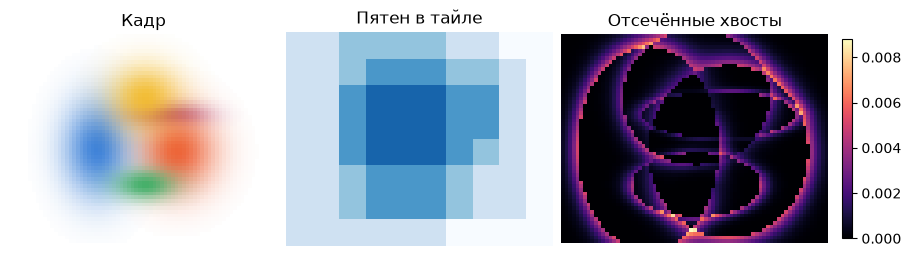

In [2]:
display(tiles_figure(lang=lang))
plt.close()
controls(lambda tile, k, angle: tiles_figure(int(tile), k, angle, lang),
         tile=[8, 4, 16, 32], k=(1., 4., .1, 3.), angle=(-45, 45, 1, 0))


### Один объект в памяти, несколько адресов на экране

У прошлого урока был счётчик гауссиан. У этого появится ещё один счётчик, и он часто показывает гораздо больше. На сцене всего пять объектов, у каждого ровно один центр в пространстве. Камера превращает центр и форму в плоский след. Один такой след может пересекать несколько клеток экрана. В каждой клетке будет короткая запись «вот номер объекта, который сюда дотягивается». Объект при этом не клонировался и расход материалов сцены не вырос. Список привязан к нынешнему кадру. После движения камеры место старой записи вполне может оказаться пустым.

Пиксельный рендерер из урока 14 мысленно начинает с вопроса «сколько красного, зелёного и синего дошло в эту точку?». Рендерер с тайлами начинает на один шаг раньше. Сначала он решает, о каких объектах в этой части изображения вообще стоит спрашивать. Для очень далёкого от пятна пикселя исходная программа всё равно вычитала координаты, измеряла расстояние в вытянутой системе осей, брала экспоненту, умножала альфу и обновляла цвет. Это пять разных видов работы ради результата, который после округления экрана почти всегда равен белому.

Есть два самостоятельных решения. Первое — установить расстояние, за которым вклад разрешено положить равным нулю. Так мы меняем определение рисуемого следа. Второе — для уже выбранной границы заранее отобрать кандидатов. Так мы меняем способ вычисления определённого кадра. Проверка вида «на глаз картинки похожи» легко смешивает эти решения. Дальше будет три изображения, с которыми можно сравниваться. Одно учитывает бесконечные хвосты, второе перебирает все пять пятен с обрезанием, третье считает ту же обрезанную модель по спискам. У каждой пары свой смысл сравнения.

## Где заканчивается мягкое пятно

Строго говоря, нигде. У одномерного колокола с центром 9 и шириной 2 точка 13 находится на $(13-9)/2=2$ ширины правее центра. Возводим 2 в квадрат, получаем 4, делим на −2 и берём экспоненту. Вес равен $e^{-2}\approx0.1353$. На трёх ширинах он ещё положителен, $e^{-9/2}\approx0.0111$. При непрозрачности 0.8 вклад в альфу на этой границе равен $0.8\cdot0.0111\approx0.0089$.

У эллипса вместо одного расстояния два. Пусть центр пиксельного следа $m=(9,6)$, ширины по осям 2 и 1 пиксель. В пикселе $p=(12,7)$ смещения составляют $3$ и $1$ пиксель. Расстояние в единицах собственных ширин, уже возведённое в квадрат,

$$
q=(3/2)^2+(1/1)^2=2.25+1=3.25.
$$

При границе $k=2$ условие $q\le k^2=4$ выполняется. Вес равен $e^{-3.25/2}\approx0.197$. При повороте эллипса из урока 13 тот же расчёт принимает вид $q=(p-m)^T S^{-1}(p-m)$, где $S$ — ковариация следа в квадратных пикселях. Обратная матрица убирает масштаб, поэтому $q$ и $k$ безразмерны. Операция отсечения в обоих вариантах одна: за границей вес равен нулю.


In [3]:
q = (3/2)**2 + (1/1)**2
print("q =", q, "weight =", np.exp(-q/2))
assert q < 2**2 and np.exp(-9/2) < .012


q = 3.25 weight = 0.19691167520419406


### Граница, прямоугольник и лишние проверки

На рисунке ниже тот же маленький пример размечен по пикселям. Кружки стоят на тех целочисленных центрах, которые прошли точную проверку. Оранжевый контур — линия двух ширин. Пунктирный прямоугольник нужен на подготовке тайлов. В левом верхнем углу прямоугольника находится пиксель $(5,4)$. От центра он на две ширины левее и на две выше. Квадрат расстояния равен $(-2)^2+(-2)^2=8$. Весь прямоугольник покрывает 9 столбцов и 5 строк, то есть 45 пиксельных центров, а точный эллипс пропускает только 25. Оставшиеся 20 — плата за лёгкую проверку границ. Отсечь пиксель чуть позже разрешено, потерять нужный пиксель раньше уже нельзя.

На самой границе принято $q\le4$, включая равенство. Поэтому крайние точки $(5,6)$ и $(13,6)$ дают ненулевой вес. Первая допустимая целая координата внутри прямоугольника находится округлением левого края **вверх**, последняя — округлением правого края **вниз**. Например, если тот же центр сдвинуть на 0.2 пикселя вправо, отрезок по горизонтали станет $[5.2,13.2]$. Целые центры займут номера от 6 до 13. При выборе тайлов границу ещё пересекаем с реальным экраном. Отрицательный столбец пикселем изображения не станет.

При повороте длинная ось обычно идёт наискось, но тайлы всё равно выровнены по сетке экрана. Поэтому в расчёт ширины прямоугольника входит дисперсия вдоль экранной горизонтали. Пусть собственные масштабы равны 2 и 1 пикселю и обе оси повернуты на 45°. Горизонтальные проекции этих масштабов имеют длины $2/\sqrt2$ и $1/\sqrt2$. Складываются квадраты, так что $S_{xx}=4/2+1/2=2.5$. Две ширины займут $2\sqrt{2.5}\approx3.16$ пикселя влево и вправо. Одинаковые горизонтальная и вертикальная границы при таком угле дали квадратный контейнер вокруг **вытянутого наклонного** следа. Для формы внутри по-прежнему нужна полная матрица, включая смешанный член.

pixel centers: box = 45 ellipse = 25


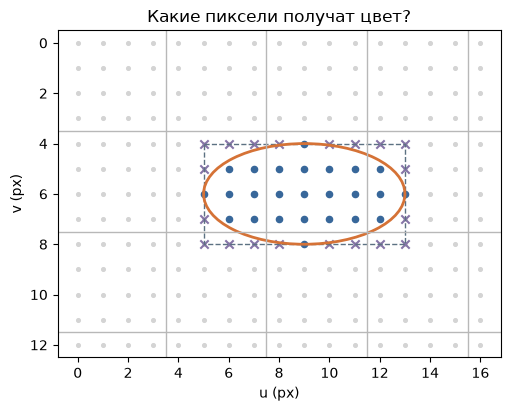

In [4]:
from matplotlib.patches import Ellipse, Rectangle
yy, xx = np.mgrid[0:13, 0:17]
q_grid = ((xx-9)/2)**2+(yy-6)**2
inside = q_grid <= 4
box = (abs(xx-9)<=4) & (abs(yy-6)<=2)
assert np.all(~inside | box)
print("pixel centers: box =", int(box.sum()), "ellipse =", int(inside.sum()))

fig, ax = plt.subplots(figsize=(7.2, 4), constrained_layout=True)
ax.scatter(xx, yy, s=7, color=".83")
ax.scatter(xx[box & ~inside], yy[box & ~inside], marker="x", color="#8675a8")
ax.scatter(xx[inside], yy[inside], color="#38679a", s=20)
ax.add_patch(Rectangle((5,4), 8,4, fill=False, linestyle="--", color="#5c7182"))
ax.add_patch(Ellipse((9,6),8,4,fill=False,edgecolor="#d57236",lw=2))
for edge in (3.5,7.5,11.5,15.5): ax.axvline(edge,c=".72",lw=1)
for edge in (3.5,7.5,11.5): ax.axhline(edge,c=".72",lw=1)
ax.set(xlabel="u (px)",ylabel="v (px)",aspect="equal",ylim=(12.5,-.5),
       title="Какие пиксели получат цвет?" if lang=="ru" else "Which pixels receive color?")
plt.show()

## От эллипса к списку тайла

Для того же пятна граница в две ширины доходит по горизонтали от $9-2\cdot2=5$ до $9+2\cdot2=13$, по вертикали от $6-2\cdot1=4$ до 8. Это прямоугольник, обнимающий эллипс. Угловой пиксель может лежать в прямоугольнике, а проверку $q\le4$ не пройти.

Если сторона тайла 4 пикселя, столбцы 0–3 принадлежат тайлу 0, 4–7 — тайлу 1. Номер равен целой части деления координаты на 4. По горизонтали наше пятно касается тайлов 1, 2, 3, по вертикали 1, 2. Получается $3\cdot2=6$ ссылок на одну гауссиану. Сами параметры цвета и формы сохраняются один раз. Для повёрнутой ковариации полуразмер прямоугольника по горизонтали равен $k\sqrt{S_{xx}}$, по вертикали $k\sqrt{S_{yy}}$. Диагонали содержат дисперсию вдоль **экранных** осей; корень возвращает пиксели.

Тест глубины убирает центр позади ближней плоскости. На самом экране одного центра мало для отбрасывания: при горизонтальной координате центра −1 и радиусе 3 пикселя след дотягивается до столбца 2. Пиксель 0 может получить цвет, хотя центр за левой границей. Поэтому со стороной кадра сравнивается прямоугольник следа.

Дальше у каждого пикселя только один список. Сначала идёт ближайший центр, затем следующий по глубине. Новое пятно получает долю $T\alpha$, где $T$ — ещё прозрачная часть луча. При $T=0.6$ и $\alpha=0.25$ цвет этого пятна входит с весом $0.15$, дальше проходит $0.6(1-0.25)=0.45$. Порядок меняет цвет, поэтому в каждом тайле сохраняется одна и та же сортировка.


In [5]:
sc = small_scene()
cam = orbit(0, 73, 57)
slow, brute = finite_render(sc, cam, 73, 57, 8, 3, tiled=False)
fast, bins = finite_render(sc, cam, 73, 57, 8, 3, tiled=True)
print("pairs:", brute["pairs"], "→", bins["pairs"])
print("max |fast − slow|:", np.max(np.abs(fast-slow)))
assert np.allclose(fast, slow, atol=1e-12, rtol=0)


pairs: 20805 → 8688
max |fast − slow|: 0.0


### Что лежало бы в отсортированном массиве

В маленькой сцене можно обойтись обычными списками Python. Для понимания GPU полезно проделать тот же проход на бумаге. Пусть красный объект R находится на глубине 5 м и дотрагивается до тайлов 0 и 1. Синий B на 2 м касается только 1, зелёный G на 4 м — только 0. После проекции есть **три** набора параметров, а после раздачи адресов получается **четыре** записи. Число записей определяется суммой пересечений, а не произведением числа объектов на число тайлов.

| До сортировки · тайл, глубина, объект | После сортировки |
|---|---|
| 0, 5, R | 0, 4, G |
| 1, 5, R | 0, 5, R |
| 1, 2, B | 1, 2, B |
| 0, 4, G | 1, 5, R |

Ключ состоит из двух частей. Сначала сравниваются номера тайлов. При равенстве сравниваются глубины центров, ближайший окажется раньше. Нулевой тайл забирает позиции массива 0 и 1, первый — 2 и 3. Границы диапазонов удобно писать как $[0,2)$ и $[2,4)$. Квадратная скобка включает левый индекс, круглая исключает правый. Красный появился дважды с одинаковым номером объекта. Так его цвет читается из одной строки хранилища, хотя обрабатывают его две группы пикселей.

Возьмём внутри тайла 1 пиксель, где у синего локальная альфа 0.5, у красного 0.6. Фон белый. Сначала синий получает 0.5 веса, красному остаётся $0.5\cdot0.6=0.3$. Фон занимает $0.5\cdot0.4=0.2$. Красная компонента равна $0.3+0.2=0.5$, зелёная $0.2$, синяя $0.5+0.2=0.7$. Если бы список собирался просто добавлением красного первым и никогда не сортировался, картинка стала бы краснее. Поэтому сортировка влияет на корректность даже при идеально подсчитанных границах. Глубина в ключе относится к центру пятна. Один порядок для всего тайла служит приближением для протяжённых пересекающихся объектов.

## Счётчик работы и часы

Кадр из 73 × 57 пикселей и пяти видимых пятен даёт 20 805 пар «пиксель, пятно» при полном переборе. Граница обнуляет часть весов, но саму проверку расстояния мы уже оплатили. Списки при стороне 8 оставляют 8 688 таких пар. В тайле из 64 пикселей один лишний кандидат стоит 64 проверки. Мелкие тайлы экономят проверки, крупные экономят ссылки и подготовку. Накладные расходы Python и размер массивов влияют на время отдельно. Для замера сначала рисуется пробный кадр, потом берётся медиана нескольких замеров настенных часов на этой машине.


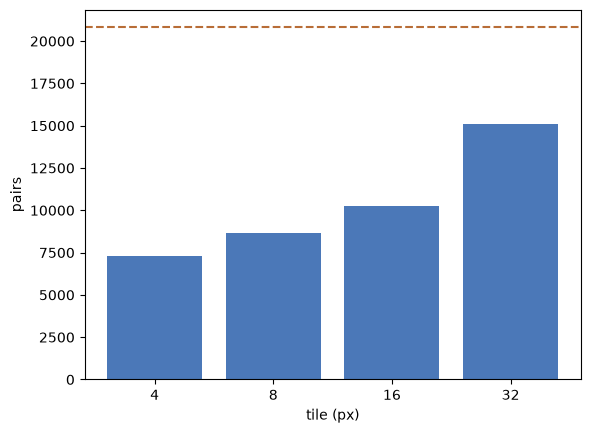

CPU ms: 5.9


In [6]:
sides = [4, 8, 16, 32]
counts = [finite_render(sc, cam, 73, 57, side)[1]["pairs"] for side in sides]
plt.bar([str(s) for s in sides], counts, color="#4b78b8")
plt.axhline(brute["pairs"], color="#b86d37", linestyle="--")
plt.ylabel("pairs"); plt.xlabel("tile (px)"); plt.show()
print("CPU ms:", round(benchmark(lambda: finite_render(sc, cam, 73, 57)), 2))


## Почему 141 запись превращается в 8 688 проверок

У нижнего края карты есть тонкая синяя полоска. Кадр не делится на восемь нацело. По горизонтали помещается девять полных плиток и один столбец шириной в пиксель. По вертикали — семь полных и одна строка высотой в пиксель. Получается таблица размером 8 строк на 10 столбцов. В средней плитке с индексами $(3,4)$ лежат четыре номера пятен. Каждому из 64 пикселей предстоит рассмотреть четыре кандидата. Получается $64\cdot4=256$ проверок. На нижней кромке у плитки $(7,4)$ всего восемь пикселей и одно пятно. Там прибавится восемь проверок. В правом нижнем углу список пуст. Даже тому единственному пикселю считать расстояния не придётся.

Из этого получается способ посчитать работу для любого прямоугольного кадра. Для каждой плитки берём **её настоящую площадь в пикселях**, умножаем на длину её списка, складываем. Если умножить все 141 записи на 64, получится 9 024. Лишние 336 проверок появились у воображаемых пикселей за правой и нижней границами. В таблице ниже первая колонка показывает цену хранения списков, вторая — сколько раз понадобилось проверять расстояние. При переходе от 4 к 32 пикселям записей становится меньше в 26 раз, а проверок почти вдвое больше. При малой плитке одно пятно попадает во множество списков. При большой даже далёкий от пятна угол получает его номер.

Теперь оставим плитку размером 8 и изменим только границу пятна. На рисунке справа у каждого пикселя свой цвет ошибки. Из трёх разностей по RGB берём самую большую по модулю. Один и тот же масштаб цветов позволяет сравнить обрезку на одной и на трёх ширинах. Белый фон тоже участвует в сравнении. На краю синего пятна отказ от слабого синего вклада открывает больше белого. Ошибка видна даже на участке, где нет других пятен.

У радиуса в одну ширину выходит 1 728 проверок, но наихудший канал промахивается примерно на 0.628 из единицы. При трёх ширинах остаётся 8 688 проверок и примерно 0.0125 ошибки. При четырёх число проверок поднимается до 12 457, а самая большая ошибка падает до 0.00039. Меньше одной ступени 8-битного цвета $1/255\approx0.00392$ на этом кадре. Эта цифра привязана к пяти пятнам, их непрозрачности и обзору. Изменившаяся сцена требует нового сравнения с полной гауссианой.

плитка | записи | проверки | CPU, мс


   4 |     464 |  7304 |   14.30
   8 |     141 |  8688 |    5.83
  16 |      46 | 10257 |    6.35


  32 |      18 | 15105 |    1.92


k=1, tests=1728, max |ΔRGB|=0.627549
k=2, tests=4992, max |ΔRGB|=0.182898
k=3, tests=8688, max |ΔRGB|=0.012470
k=4, tests=12457, max |ΔRGB|=0.000391


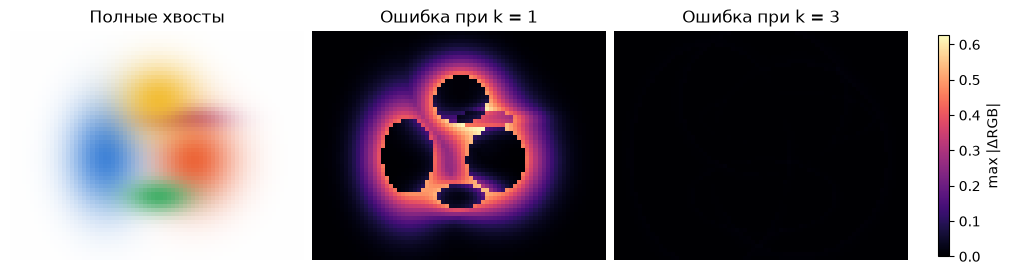

In [7]:
labels = {"ru": ("Полные хвосты", "Ошибка при k = 1", "Ошибка при k = 3", "плитка | записи | проверки | CPU, мс"),
          "en": ("Full tails", "Error at k = 1", "Error at k = 3", "tile | entries | tests | CPU ms")}[lang]
print(labels[3])
for side in [4, 8, 16, 32]:
    _, stats = finite_render(sc, cam, 73, 57, side, 3)
    areas = np.array([[min(side, 57-y)*min(side, 73-x)
                       for x in range(0, 73, side)] for y in range(0, 57, side)])
    assert np.sum(stats["tiles"] * areas) == stats["pairs"]
    ms = benchmark(lambda: finite_render(sc, cam, 73, 57, side, 3), repeats=3)
    print(f"{side:4} | {stats['references']:7} | {stats['pairs']:5} | {ms:7.2f}")
full = render_scene(sc, cam, 73, 57)
errors = {}
for k in [1, 2, 3, 4]:
    cut, stats = finite_render(sc, cam, 73, 57, tile=8, cutoff=k)
    errors[k] = np.max(np.abs(cut-full), axis=2)
    print(f"k={k}, tests={stats['pairs']}, max |ΔRGB|={errors[k].max():.6f}")
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
axes[0].imshow(full)
for ax, k in zip(axes[1:], [1, 3]):
    im = ax.imshow(errors[k], cmap="magma", vmin=0, vmax=errors[1].max())
fig.colorbar(im, ax=axes[1:].tolist(), shrink=.76, label="max |ΔRGB|")
for ax, title in zip(axes, labels[:3]):
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## Где здесь оригинальная статья

У Kerbl, Kopanas, Leimkühler и Drettakis есть три связанные части. Обучаемые трёхмерные гауссианы хранят форму и цвет, изменение плотности добавляет или убирает элементы, а растеризатор быстро превращает текущую сцену в кадр. Уже знакомая нам ошибка изображения проходит через этот рендерер обратно в параметры. В учебном коде обход списков виден строка за строкой.

Реализация авторов сначала отсеивает невидимые центры, проецирует форму и вычисляет экранный радиус. Для каждой пары «пятно, тайл» появляется запись с номером тайла и глубиной. После сортировки соседние записи одного тайла образуют диапазон. Блок потоков GPU обрабатывает участок экрана, подгружая кандидатов порциями в общую память. Потоки считают свои пиксели одновременно. Там также есть экранная фильтрация, порог очень малой альфы, ограничение альфы сверху и ранняя остановка при малой прозрачности. Поэтому равенство двух наших массивов проверяет именно учебный алгоритм с **одним** порогом. Число миллисекунд выше относится к CPU и этому размеру кадра.

[Статья и результаты](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) · [Подготовка и сортировка тайлов](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/rasterizer_impl.cu) · [Обработка пикселей на GPU](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu)

## Что можно накопить один раз и что нужно для обратного прохода

Если в плитке 256 пикселей, многим нужны одни и те же центры, цвета и формы. В исходном GPU-рендерере блок из $16\times16$ потоков загружает очередную порцию кандидатов в общую память блока. Каждый поток читает эти параметры для своего пикселя и ведёт два собственных числа для одного цветового канала — уже набранный цвет и остающуюся прозрачность $T$. При $T=0.02$ всё, что находится дальше, может распорядиться лишь двумя сотыми общей доли. Даже замена оставшейся части белым вместо чёрного изменила бы канал максимум на 0.02. На этом основана остановка для почти закрытого пикселя. Когда все пиксели плитки закончили работу, следующих кандидатов можно вообще не загружать.

У обратного прохода другая задача. Пришлось ли затемнить кадр из-за переднего пятна или из-за дальнего? Возьмём один серый канал. Цвет переднего пятна 0.2, дальнего 0.8, фона 1. Их непрозрачности в этом пикселе равны 0.5 и 0.6. За передним пятном видна смесь $0.6\cdot0.8+0.4\cdot1=0.88$. Итоговый серый равен $0.5\cdot0.2+0.5\cdot0.88=0.54$. Дополнительная сотая непрозрачности переднего пятна забирает сотую долю смеси 0.88 и заменяет её цветом 0.2. Канал меняется на $0.01(0.2-0.88)=-0.0068$. Та же прибавка дальнему пятну заменяет белый на 0.8, и от этой замены через переднее проходит половина. Получается $0.5\cdot0.01(0.8-1)=-0.001$. Даже на одном пикселе два параметра получают разные поправки.

В исходной реализации при обратном обходе та же плитка проходит список с дальнего конца. Из сохранённых для пикселя прозрачности и позиции последнего участника восстанавливаются доли, нужные для производных. Хранить отдельное изображение для каждого пятна не приходится. Дальше градиенты экрана идут через проекцию в параметры сцены, как в уроке 16. Раскладка по плиткам ускоряет и этот обход. На кадре с несколькими огромными перекрывающимися полупрозрачными пятнами выигрыш может исчезнуть. Все плитки получили одни и те же номера, а прозрачности ещё хватает, чтобы видеть дальние слои.

## Опыт

Что произойдёт с картинкой при переходе от тайла 4 к тайлу 32 и той же границе? А если оставить тайл 4, но срезать пятно уже на одной ширине?

<details><summary>Разбор</summary>

В первом случае поменяются длины списков и число проверок. Веса пикселей и итоговый цвет совпадут. Во втором пропадут даже участки, где вес был около 0.6. Светлые промежутки расширятся. Разность с полным колоколом объясняется сменой поддержки, а не сортировкой.

</details>


## Ещё три маленьких сцены

### Хвост одного пятна и десять хвостов

Десять одинаковых чёрных пятен на белом дают в выбранном пикселе $\alpha=0.01$ каждое. Как далеко от белого окажется пиксель, если сохранить эти хвосты?

<details><summary>Разбор</summary>

Через первое пятно проходит 0.99 белого, через второе $0.99^2=0.9801$. После десяти остаётся $0.99^{10}\approx0.9044$. Сами пятна чёрные и ничего к каналу не добавляют. Обрезав все десять, получим 1 вместо 0.9044. Ошибка 0.0956 заметно больше сотой у любого одного слоя. Порог отдельного вклада ещё не гарантирует такой же границы ошибки всего кадра.

</details>

### Двухпиксельный край

Кадр 10 × 4 разрезан на плитки 4 × 4. В списках слева направо лежат два, три и один номер. Сколько записей хранится, сколько пар проверится и что даст расчёт без списков, если в камеру попало пять пятен?

<details><summary>Разбор</summary>

Длины складываются в $2+3+1=6$ записей. У первых двух плиток по 16 пикселей, у последней всего $2\cdot4=8$. Получается $16\cdot2+16\cdot3+8\cdot1=88$ проверок. Полный перебор требует $10\cdot4\cdot5=200$. Сохранив 6 записей, мы сэкономили 112 проверок. Миллисекунды зависят ещё и от цены подготовки и обхода этих списков.

</details>

### Пять огромных стёкол

Те же пять пятен выросли до размеров кадра 73 × 57 и задевают каждую плитку. Их непрозрачность в центре 0.1. Есть ли смысл ожидать прежней экономии при размере плитки 8?

<details><summary>Разбор</summary>

Теперь у всех 80 плиток по пять номеров. В списках 400 записей, а число проверок снова $73\cdot57\cdot5=20\,805$. Ограничивающие прямоугольники никого не отсеяли. Даже если в центре каждого стекла непрозрачность максимальна, после пяти слоёв ещё проходит $0.9^5\approx0.5905$ света, далеко от полного закрытия. Ранний выход здесь почти не поможет. Для новой сцены имеет смысл отдельно измерить время подготовки и обработки кадра, прежде чем выбирать размер плитки.

</details>